In [2]:
import numpy as np
import matplotlib.pyplot as plt


C:\Users\tangr\AppData\Roaming\Python\Python310\site-packages\matplotlib\projections\__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [6]:
a = np.loadtxt("../temp/Faux-Monnayeurs-outlet_2D.txt")

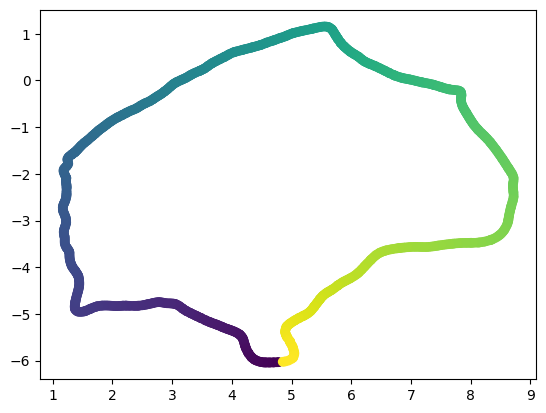

In [7]:
plt.scatter(*a.T, c = np.arange(len(a)))

In [41]:
def angle(a,b,c):
    ba = b-a
    bc = b-c

    angle = np.arccos(np.dot(ba, bc) / (np.linalg.norm(ba)*np.linalg.norm(bc)))
    return angle

In [42]:
P = list(a[::-1])

angle(P[0],P[1], P[2])

1.5707963267948966

In [306]:
shape = np.array([[0,1],[1,1],[1,2],[0.5,1.5], [0.25, 1.6],[0,2], [0,1.5]]) #square

In [352]:
def is_not_reflex(a,b,c):
    return np.cross(b-a, c-b) >=0

In [353]:
def lpvs(shape):
    LPVS = []
    for i in range(len(shape)):
        a = np.roll(shape, -1, axis=0)[i]
        b = shape[i]
        c = np.roll(shape, 1, axis=0)[i]

        if not is_not_reflex(a,b,c):
            LPVS.append(i)
    return LPVS

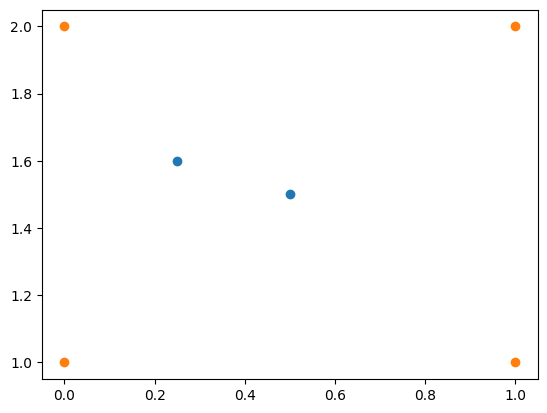

In [ ]:
fig, ax = plt.subplots()

reflexes = np.array([elem in lpvs(shape[::-1]) for elem in range(0, len(shape))])

ax.scatter(*shape[::-1][reflexes].T, label = "reflex")
ax.scatter(*shape[::-1][~reflexes].T, label = "non-reflex")


In [516]:
# algorithm MP1 from fernandez. Polygon into convex decomposition. 
shape = np.array([[0.5, 1.2],[1,1],[0.8, 1.5], [1,2],[0.5,1.5], [0.25, 1.6],[0,2], [0,1] ]) #square


a = shape[::-1]

reflexes = np.array([elem in lpvs(a) for elem in range(0, len(a))])

# step 1. # read in clockwise order the vertices. 
c = np.mean(a, axis = 0)
# determine the order by calculating the signed area of the polygon. 
# A should be positive if the polygon is given in counter-clockwise order, negative otherwise.
A = 0
for i in range(len(a)):
    A+= np.cross(c-a[i], c-np.roll(a,1, axis=0)[i]) / 2

if A > 0:
    P = list(a)
else:
    P = list(a[::-1])

Parray = np.array(P)

Polygons = []



v1_arg=0
L= [[P[0]]] # this will contain the subset of vertices for the polygons.
L_args =[[v1_arg]]
m = 1
n  = len(Parray)
P_args = list(range(len(P)))

kit = 0
while n > 3 and kit < 10:
    print("P_args at begin", P_args)
    # do the MP1 algorithm.
    # 3.1
    P = Parray[P_args]

    v1 = P[0]
    v1_arg = 0
    # choose last vertex of previous polygon.
    v2 = P[1] # choose the next vertex along in the polygon path
    v2_arg = 1
    print("v1_arg", v1_arg)
    print("v2_arg", v2_arg)

    # 3.2
    L.append([v1, v2])
    L_args.append([P_args[v1_arg], P_args[v2_arg]])

    i = 2

    vi_next = P[v1_arg+i]
    vi= P[v1_arg+i-1]
    vi_prev = P[v1_arg+i-2]

    print("indices for reflex check of vi+1 :", v1_arg+i, v1_arg+i-1, v1_arg+i-2, v1_arg, v2_arg)
    
    # 3.3 add vertices while not adding reflexes

    check1 = is_not_reflex(vi_prev,vi,vi_next)

    print(check1, angle(vi_prev,vi,vi_next))
    while not is_not_reflex(vi_prev,vi,vi_next) and not (is_not_reflex(vi,vi_next,v1) and is_not_reflex(vi_next,v1,v2)) and len(L[m]) < n:

        L[m].append(vi_next)
        L_args[m].append(P_args[v1_arg+i])
        
        i+=1
        if len(L[m]) < n:
            vi_next = P[v1_arg+i]
            vi= P[v1_arg+i-1]
            vi_prev = P[v1_arg+i-2]

    # 3.4 check whether this has finished.
    if len(L[m]) != len(P):
        print(L[m])
        print("there were notches.")

        # 3.4.1: list of vi which are notches. (excluding those in L already.)
        # set of vertices in L.
        print("m is now", m)
        print("set of P_args", set(P_args), set(L_args[m]))
        P_exclude_Lm = set(P_args) - set(L_args[m])

        print("finding the notches indices within the possible indices: ", P_exclude_Lm)
        subset = P_exclude_Lm

        reflexes = set(lpvs(Parray))
        LPVS_args = list(set.intersection(subset, reflexes))
        shape_P_exclude_L = Parray[list(subset)]
 
        print("LVPS args", LPVS_args)
        
        R = [np.min(np.array(L[m])[:, 0]), 
             np.max(np.array(L[m])[:, 0]),
             np.min(np.array(L[m])[:, 1]),
             np.max(np.array(L[m])[:, 1])]
        
        if len(LPVS_args) == 0:
            print("no vertices wihin excluded set are notches")
        
        backward = False
        while backward == False and len(LPVS_args) > 0:

            # check whether v is in rect R.

            # repeat and keep. 
            v_in_r = False
            while v_in_r == False and len(LPVS_args) > 0:
                v_arg = LPVS_args[0]
                v = Parray[v_arg]
                
                if not (v[0] < R[1] and v[0] > R[0] and v[1] < R[3] and v[1] > R[2]):
                    print(f"v is not in R {v}")
                    # v is not in R.
                    LPVS_args.pop(0) 
                else:
                    v_in_r = True
                    print("vertex v in the rectangle!")
            
            if len(LPVS_args)>0:
                print("we have reached a new condition.")
                print(R)
                print(v)
                # obtain the set of VTR vertices contained in the semi-half plane
                # generated by
                # 
                # semi plane. 

                v1v = v1-v
                vlast = L[m][-1]
                vlast_arg = L_args[m][-1]

                print("trying to check the semi-plane.")
                print("vlast_arg", vlast_arg)
                LPVS_args.pop(0)
                backward== True
            else:
                print("removed all possible vertices, none were in R")
                

                # end MP1.
        # if no notches in excluded set, then no need of backward.
        cond = np.allclose(Parray[v2_arg]- L[m][-1], np.zeros(2), atol=1e-4)
        print("the condition is not met", not cond)
        print(v2_arg, Parray[v2_arg])
        
        if not cond:

            print("some condition not met")  
            # we write the partition

            if len(L[m]) == 2:
                print("two point segment.")
                print(L[m])
                L[m].append(Parray[P_args[-1]])
                L[m] =  [L[m][-1]] + L[m][:-1]
                L_args[m].append(P_args[-1])
                L_args[m] = [L_args[m][-1]]+ L_args[m][:-1]
            
            Polygons.append(np.array(L[m]))

            P_args = [L_args[m][-1]]+ list(set(P_args)-set(L_args[m])) + [L_args[m][0]]
            print(P_args)
            n = len(P_args)
        
        
    else:
        cond = np.allclose(Parray[v2_arg]- L[m][-1], np.zeros(2), atol=1e-4)
        print("the condition is not met", not cond)
        print(v2_arg, Parray[v2_arg])
        if not cond:
            print("some condition not met")  
            # we write the partition
            Polygons.append(np.array(L[m]))

            P_args = [L_args[m][-1]]+ list(set(P_args)-set(L_args[m])) + [L_args[m][0]]
            print(P_args)
            n = len(P_args)
    m+=1
    kit+=1
    
if n == 3:
    Polygons.append(Parray[P_args]) 

P_args at begin [0, 1, 2, 3, 4, 5, 6, 7]
v1_arg 0
v2_arg 1
indices for reflex check of vi+1 : 2 1 0 0 1
False 0.5585993153435626
[array([0., 1.]), array([0., 2.]), array([0.25, 1.6 ])]
there were notches.
m is now 1
set of P_args {0, 1, 2, 3, 4, 5, 6, 7} {0, 1, 2}
finding the notches indices within the possible indices:  {3, 4, 5, 6, 7}
LVPS args [3, 5, 7]
v is not in R [0.5 1.5]
v is not in R [0.8 1.5]
v is not in R [0.5 1.2]
removed all possible vertices, none were in R
the condition is not met True
1 [0. 2.]
some condition not met
[2, 3, 4, 5, 6, 7, 0]
P_args at begin [2, 3, 4, 5, 6, 7, 0]
v1_arg 0
v2_arg 1
indices for reflex check of vi+1 : 2 1 0 0 1
True 1.9756881130799797
[array([0.25, 1.6 ]), array([0.5, 1.5])]
there were notches.
m is now 2
set of P_args {0, 2, 3, 4, 5, 6, 7} {2, 3}
finding the notches indices within the possible indices:  {0, 4, 5, 6, 7}
LVPS args [5, 7]
v is not in R [0.8 1.5]
v is not in R [0.5 1.2]
removed all possible vertices, none were in R
the condition

In [550]:
from subprocess import check_output
import json

In [551]:
header = """const { decompose } = require('fernandez-polygon-decomposition');

"""
footer = """const convexPartition = decompose(polygon);

console.log(convexPartition);

const FileSystem = require("fs");
 FileSystem.writeFile('example.json', JSON.stringify(convexPartition), (error) => {
    if (error) throw error;
  });"""

In [552]:
def decompose(polygon):
    # write a js file. 

    with open("polygon.js", "w") as f:
        f.write(header)
        f.write("const polygon = [")

        f.write(f"{{x: {polygon[0,0]}, y:{polygon[0,1]}}},\n")
        for elem in polygon[1:-1]:
            f.write(f"\t\t{{x: {elem[0]}, y:{elem[1]}}},\n")
        f.write(f"\t\t{{x: {polygon[-1,0]}, y:{polygon[-1,1]}}},\n")
        f.write("];\n\n")
        f.write(footer)
        f.close()

    _ = check_output("node polygon.js")

    with open("example.json" , "r") as f:
        y = json.load(f)
        f.close()

    convex_poly = []
    for triangle in y:
        triangle_array = np.zeros((len(triangle), 2))
        for c, vertex in enumerate(triangle):
            triangle_array[c] = [vertex["x"], vertex["y"]]
        
        convex_poly.append(triangle_array)

    return convex_poly
        

In [553]:
a = np.loadtxt("../temp/Faux-Monnayeurs-outlet_2D.txt")
a = a[::-1]

convex_polygons_a = decompose(a)


b = np.loadtxt("../temp/Faux-Monnayeurs-inlet_2D.txt")
b = b[::-1]

convex_polygons_b = decompose(b)


In [555]:
# compute the minkovski sm

def slope_line(p1,p2): #takes in two points and finds the slope of line joining them
    m = p2-p1
    if np.arctan2(m[1],m[0]) >= 0:
        return np.arctan2(m[1],m[0])
    else:
        return 2*np.pi + np.arctan2(m[1],m[0])
    
# minkovski sum is easy if both are convex. 
def minkovski_sum(a, b, wa):

    i = 0 
    j = 0
    wb = 1-wa
    minkowski_sum_vertices = []  # Collecting vertices of the minkowski sum
        
    minkowski_sum_vertices.append(wa*a[i]+wb*b[j])
        
    while not((i==len(a)-1) and (j==len(b)-1))  :
        if i == len(a)-1:
                j = j+1
        elif j == len(b)-1:
                i = i+1
        elif slope_line(a[i],a[i+1]) < slope_line(b[j],b[j+1]) : #selecting the next vertex depending on angle transition
                i = i+1
        elif slope_line(a[i],a[i+1]) > slope_line(b[j],b[j+1]): #selecting the next vertex depending on angle transition
                j = j+1
        else:
                i = i+1
                j = j+1
        
        minkowski_sum_vertices.append(wa*a[i]+wb*b[j])
            
    return np.array(minkowski_sum_vertices)

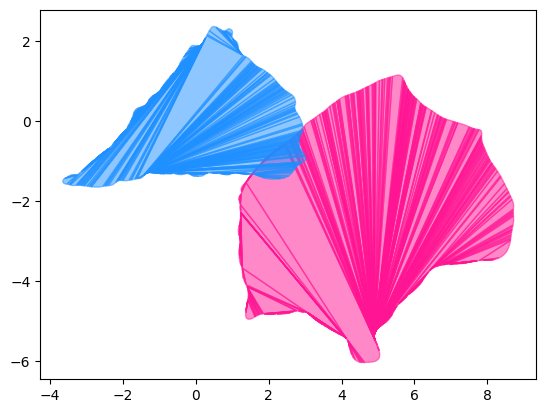

In [554]:
fig, ax = plt.subplots()

for triangle in convex_polygons_a:
    ax.fill(*triangle.T, color = "deeppink", alpha = 0.5)

for triangle in convex_polygons_b:
    ax.fill(*triangle.T, color = "dodgerblue", alpha = 0.5)

In [580]:
from shapely import union_all, union, Polygon, GEOSException

In [ ]:
sums = []
previous = Polygon([[0,0],[0,0],[0,0]])

for i in range(len(convex_polygons_a)):
    for j in range(len(convex_polygons_b)):
        new = Polygon(minkovski_sum(convex_polygons_a[i], convex_polygons_b[j],  wa = 0.5))
        sums.append(new)


invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...
invalid topology...


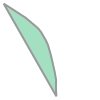

In [575]:
union(sums[0], sums[1])